# 07h Time-series comparison

This is where all the time-series models meet on one backtest: the same 150 products, the same six scored origins,
the same 28 days and the same metric code as 07a. Eight contenders are in the headline: seasonal naive, damped ETS,
SARIMA, SARIMAX, Theta, Prophet, AutoTS and a combination of the strongest ones. The combination is built here, from
validation results only. The building blocks (AR, MA, ARMA, ARIMA, ARIMAX) are shown below the headline, and VARIMA
on the totals in its own table. The reference throughout is SARIMA as it was in 07a: RMSE 4.445, MAE 3.522.

## Load what the other notebooks saved

Each notebook wrote its forecasts at all nine origins. If one is missing, the comparison runs without it and says so.

In [1]:
import sys, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import ROOT, TABLES, FIGS, EVAL_ORIGINS, CATEGORIES, FIG_STYLE, SEED
import ts_models as tm
from evaluation import METRICS, mase_scales
from metrics import paired_test, holm_adjust

plt.rcParams.update(FIG_STYLE)
written = []

inp = tm.load_inputs()
sample = inp["sample"]
scales = mase_scales(inp["daily"], tm.ALL_ORIGINS)
files = {"07c": "ts_blocks_forecasts.parquet", "07d": "ts_sarima_forecasts.parquet", "07f": "ts_other_forecasts.parquet"}
parts = []
for nb, f in files.items():
    if (TABLES / f).exists():
        x = pd.read_parquet(TABLES / f)
        parts.append(x[["item_id", "origin", "date", "model", "forecast", "converged", "fallback"]])
        print(f"{nb}: {f}, models {sorted(x['model'].unique())}")
    else:
        print(f"{nb}: {f} not found, left out")
fc = pd.concat(parts, ignore_index=True)
fc["model"] = fc["model"].replace({"sarima_base": "sarima_07a"})
fc = fc[fc["item_id"].isin(sample["item_id"])]
cov = fc.groupby("model").agg(products=("item_id", "nunique"), origins=("origin", "nunique"))
print()
print(cov.to_string())

07c: ts_blocks_forecasts.parquet, models ['ar', 'arima', 'arma', 'ma']
07d: ts_sarima_forecasts.parquet, models ['arimax', 'ets', 'sarima', 'sarima_base', 'sarimax', 'seasonal_naive']
07f: ts_other_forecasts.parquet, models ['autots', 'prophet', 'theta']



                products  origins
model                            
ar                   150        9
arima                150        9
arimax               150        9
arma                 150        9
autots               150        9
ets                  150        9
ma                   150        9
prophet              150        9
sarima               150        9
sarima_07a           150        9
sarimax              150        9
seasonal_naive       150        9
theta                150        9


## The blow-up guard from 09

09 found SARIMA forecasts outside the sample that ran to hundreds of times what a product had ever sold, and added a
guard: a forecast above three times the most the product sold in its training window falls back to seasonal naive,
as a failed fit does (`docs/PREREGISTRATION_TS.md`, change 4). The same guard applies here, to every model at every
origin, so 07h scores the forecasts exactly as 09 makes them. It only looks at the training data, never at the
scored days. The files of 07c, 07d and 07f are left as they were run.

In [2]:
import best_model as bm
fit_days = {}
for m in fc["model"].unique():
    try:
        fit_days[m] = bm.spec_of(m).get("fit_days", tm.FIT_DAYS)        # ETS Box-Cox fits on all history (None)
    except (KeyError, FileNotFoundError):
        pass                                                            # building blocks and AutoTS: the 730-day window
fc, caught = bm.cap_forecasts(fc, inp["daily"], fit_days)
caught.to_csv(TABLES / "ts_capped_forecasts.csv", index=False)
written.append(TABLES / "ts_capped_forecasts.csv")
print(f"{len(caught)} of {fc.groupby(['item_id', 'origin', 'model']).ngroups:,} forecasts replaced by seasonal naive")
caught

2 of 17,550 forecasts replaced by seasonal naive


,item_id,origin,model,forecast_max,training_max
0,FOODS_3_203,2015-12-06,sarimax,193.233716,38.0
1,HOUSEHOLD_1_217,2016-01-03,sarimax,2263.341759,23.0


## The combination, chosen on validation

The members are the three contenders with the lowest validation median RMSE (ties broken by MAE), out of ETS,
SARIMA, SARIMAX, Theta, Prophet and AutoTS, counting only those with validation forecasts for all 150 products. The
headline version is a plain average. The second version weights each member, per product, by one over its mean
squared error on that product at the validation origins.

In [3]:
SINGLE = ["ets", "sarima", "sarimax", "theta", "prophet", "autots"]
full = cov[(cov["products"] == 150) & (cov["origins"] == 9)].index
avail = [m for m in SINGLE if m in full]
val_m = tm.item_scores(tm.for_tuning(fc[fc["model"].isin(avail)]), inp["actuals"], scales)
val_med = tm.medians(tm.per_item(val_m, tm.VAL_ORIGINS)).loc[avail]
members = list(val_med.sort_values(["rmse", "mae"]).index[:3])
print("validation medians of the candidates:")
print(val_med[["rmse", "mae", "mape"]].sort_values("rmse").round(3).to_string())
print("\nmembers:", members, "| left out:", [m for m in SINGLE if m not in avail])

w = val_m[val_m["model"].isin(members)].assign(mse=lambda d: d["rmse"] ** 2)
w = w.groupby(["item_id", "model"], as_index=False)["mse"].mean().assign(w=lambda d: 1 / d["mse"].clip(lower=1e-9))
comb = tm.combine(fc, members, name="combination")
comb_w = tm.combine(fc, members, weights=w, name="combination_weighted")
fc = pd.concat([fc, comb, comb_w], ignore_index=True)
pd.DataFrame({"member": members, "validation_rmse": val_med.loc[members, "rmse"].to_numpy(),
              "validation_mae": val_med.loc[members, "mae"].to_numpy()}).to_csv(TABLES / "ts_combination_members.csv", index=False)
written.append(TABLES / "ts_combination_members.csv")
w.to_csv(TABLES / "ts_combination_weights.csv", index=False)
written.append(TABLES / "ts_combination_weights.csv")
w.groupby("model")["w"].median().rename("median weight before normalising")

validation medians of the candidates:
          rmse    mae   mape
model                       
sarimax  4.600  3.676  0.628
ets      4.606  3.682  0.581
theta    4.691  3.759  0.632
sarima   4.697  3.814  0.647
autots   4.742  3.727  0.627
prophet  4.774  3.868  0.640

members: ['sarimax', 'ets', 'theta'] | left out: []


model
ets        0.044858
sarimax    0.044542
theta      0.042690
Name: median weight before normalising, dtype: float64

## The headline table

Each product's mean over the six scored origins, then the median across products. Validation medians are next to
them, for the record.

In [4]:
KIND = {"seasonal_naive": "contender", "ets": "contender", "sarima": "contender", "sarimax": "contender",
        "theta": "contender", "prophet": "contender", "autots": "contender", "combination": "contender",
        "combination_weighted": "combination, second version",
        "ar": "building block", "ma": "building block", "arma": "building block", "arima": "building block",
        "arimax": "building block", "sarima_07a": "reference (07a)"}
NAME = {"seasonal_naive": "Seasonal naive", "ets": "Damped Holt-Winters (ETS)", "sarima": "SARIMA",
        "sarimax": "SARIMAX", "theta": "Theta", "prophet": "Prophet", "autots": "AutoTS", "combination": "Combination",
        "combination_weighted": "Combination, inverse-error weights",
        "ar": "AR(p)", "ma": "MA(q)", "arma": "ARMA(p, q)", "arima": "ARIMA", "arimax": "ARIMAX",
        "sarima_07a": "SARIMA as in 07a"}
models = [m for m in KIND if m in set(fc["model"])]
fc = fc[fc["model"].isin(models)]
m_all = tm.item_scores(fc, inp["actuals"], scales)
m_all = m_all.merge(sample[["item_id", "category"]], on="item_id")
pi = tm.per_item(m_all, EVAL_ORIGINS).merge(sample[["item_id", "category"]], on="item_id")
pi_val = tm.per_item(m_all, tm.VAL_ORIGINS)
excl = m_all[m_all["origin"].isin(EVAL_ORIGINS)]
head = tm.medians(pi).loc[models]
head = head.join(tm.medians(pi_val, ["rmse", "mae", "mape"]).add_prefix("val_"))
head.insert(0, "kind", [KIND[m] for m in head.index])
head.insert(0, "name", [NAME[m] for m in head.index])
head["n_products"] = pi.groupby("model")["item_id"].nunique()
head["fallback_rate"] = tm.fit_stats(fc).reindex(models)["fallback_rate"]
head.index.name = "model"
head.to_csv(TABLES / "ts_headline.csv")
written.append(TABLES / "ts_headline.csv")
ref = head.loc["sarima_07a"]
print(f"MAPE leaves out {excl['mape_excluded'].mean():.1%} of the scored product-days, because nothing sold on them.")
head[["name", "kind", "rmse", "mae", "mape", "smape", "wape", "mase", "val_rmse", "val_mae"]].round(3)

MAPE leaves out 5.4% of the scored product-days, because nothing sold on them.


,name,kind,rmse,mae,mape,smape,wape,mase,val_rmse,val_mae
model,,,,,,,,,,
seasonal_naive,Seasonal naive,contender,6.039,4.720,0.753,0.616,0.581,0.973,6.165,4.857
ets,Damped Holt-Winters (ETS),contender,4.513,3.543,0.560,0.474,0.434,0.744,4.606,3.682
sarima,SARIMA,contender,4.445,3.522,0.603,0.474,0.435,0.755,4.697,3.814
sarimax,SARIMAX,contender,4.583,3.650,0.609,0.466,0.441,0.760,4.600,3.676
theta,Theta,contender,4.541,3.510,0.602,0.480,0.442,0.756,4.691,3.759
prophet,Prophet,contender,4.913,3.859,0.622,0.482,0.445,0.760,4.774,3.868
autots,AutoTS,contender,4.848,3.885,0.626,0.502,0.466,0.831,4.742,3.727
combination,Combination,contender,4.392,3.499,0.586,0.469,0.437,0.747,4.608,3.660
combination_weighted,"Combination, inverse-error weights","combination, second version",4.400,3.499,0.586,0.469,0.436,0.746,4.559,3.660


In [5]:
by_cat = pi.groupby(["category", "model"])[METRICS].median().reset_index()
by_cat.to_csv(TABLES / "ts_headline_by_category.csv", index=False)
written.append(TABLES / "ts_headline_by_category.csv")
by_cat.pivot(index="model", columns="category", values="rmse").reindex(models).rename(index=NAME).round(3)

category,FOODS,HOBBIES,HOUSEHOLD
model,,,
Seasonal naive,10.318,4.221,4.711
Damped Holt-Winters (ETS),8.150,3.131,3.660
SARIMA,7.998,3.179,3.646
SARIMAX,8.155,3.213,3.696
Theta,8.159,3.208,3.708
Prophet,8.350,3.143,3.739
AutoTS,8.919,3.388,4.106
Combination,8.005,3.167,3.663
"Combination, inverse-error weights",8.001,3.168,3.664


## The winner, for the rest of the project

The contender with the lowest median RMSE on the scored origins is the forecast the stock notebooks use from now on
(decided before this table was seen; `docs/PREREGISTRATION_TS.md`, change 2). We save its settings, member by member,
so 09 can fit exactly the same model on all 726 products.

In [6]:
import json
from config import PROCESSED
winner = head.loc[[m for m in models if KIND[m] == "contender"], "rmse"].idxmin()
setting = {}
for f in ["ts_sarima_forecasts.parquet", "ts_other_forecasts.parquet"]:
    if (TABLES / f).exists():
        s = pd.read_parquet(TABLES / f, columns=["model", "setting"]).drop_duplicates("model")
        setting.update(dict(zip(s["model"], s["setting"])))

def spec_of(m):
    s = json.loads((PROCESSED / "ts_fits" / setting[m] / "spec.json").read_text())["spec"]
    return {k: v for k, v in s.items() if k not in ("order", "sorder")}      # SARIMA orders are per product

parts_ = members if winner == "combination" else [winner]
best = {"model": winner, "name": NAME[winner], "members": {m: spec_of(m) for m in parts_},
        "rmse": float(head.loc[winner, "rmse"]), "mae": float(head.loc[winner, "mae"]), "mape": float(head.loc[winner, "mape"])}
(TABLES / "ts_best_model.json").write_text(json.dumps(best, indent=1))
written.append(TABLES / "ts_best_model.json")
print(json.dumps(best, indent=1))

{
 "model": "combination",
 "name": "Combination",
 "members": {
  "sarimax": {
   "kind": "sarima",
   "exog": [
    "fourier1"
   ]
  },
  "ets": {
   "kind": "ets",
   "fit_days": null,
   "how": "boxcox"
  },
  "theta": {
   "kind": "theta"
  }
 },
 "rmse": 4.3918913580547585,
 "mae": 3.498853485229379,
 "mape": 0.5863098261945383
}


## Tests against SARIMA as in 07a

Paired Wilcoxon signed-rank tests on each product's scored RMSE, MAE and MAPE, each model against the 07a SARIMA.
Holm correction within each metric. A negative median difference means the model has the smaller error.

In [7]:
wide = {k: pi.pivot(index="item_id", columns="model", values=k) for k in ["rmse", "mae", "mape"]}
tests = []
for k, wd in wide.items():
    rows = [{"metric": k, "model": m, **paired_test(wd[m] - wd["sarima_07a"], seed=SEED)} for m in models if m != "sarima_07a"]
    for r, p in zip(rows, holm_adjust([r["p_value"] for r in rows])):
        r["p_holm"] = p
        r["better_than_sarima"] = bool(r["median_diff"] < 0 and p < 0.05)
        r["worse_than_sarima"] = bool(r["median_diff"] > 0 and p < 0.05)
    tests += rows
tests = pd.DataFrame(tests)
tests.to_csv(TABLES / "ts_tests.csv", index=False)
written.append(TABLES / "ts_tests.csv")
tests.pivot(index="model", columns="metric", values="p_holm").reindex([m for m in models if m != "sarima_07a"]).rename(index=NAME).round(4)

metric,mae,mape,rmse
model,,,
Seasonal naive,0.0000,0.0000,0.0000
Damped Holt-Winters (ETS),0.1205,0.0000,0.2624
SARIMA,NaN,NaN,NaN
SARIMAX,0.0187,0.3019,0.0006
Theta,0.7320,0.3019,0.3079
Prophet,0.0174,0.0066,0.1541
AutoTS,0.0000,0.0006,0.0000
Combination,0.0010,0.0000,0.0304
"Combination, inverse-error weights",0.0005,0.0000,0.0197


In [8]:
tests[tests["metric"] == "rmse"].set_index("model")[["median_diff", "ci_low", "ci_high", "share_improved", "p_holm"]].rename(index=NAME).round(4)

,median_diff,ci_low,ci_high,share_improved,p_holm
model,,,,,
Seasonal naive,1.3976,1.1428,1.6671,0.0133,0.0000
Damped Holt-Winters (ETS),0.0084,-0.0124,0.0298,0.4733,0.2624
SARIMA,0.0000,NaN,NaN,0.0000,NaN
SARIMAX,0.0181,0.0097,0.0379,0.3267,0.0006
Theta,-0.0024,-0.0154,0.0162,0.5200,0.3079
Prophet,0.0211,-0.0094,0.0540,0.4533,0.1541
AutoTS,0.4051,0.3167,0.5356,0.0733,0.0000
Combination,-0.0238,-0.0412,-0.0057,0.6333,0.0304
"Combination, inverse-error weights",-0.0242,-0.0418,-0.0075,0.6267,0.0197


## Which contender wins which product

For each product, the contender with the lowest scored RMSE (and, separately, MAE).

In [9]:
CONT = [m for m in models if KIND[m] == "contender"]
wins = pd.DataFrame({k: wide[k][CONT].idxmin(axis=1).value_counts() for k in ["rmse", "mae"]}).reindex(CONT).fillna(0).astype(int)
wins.to_csv(TABLES / "ts_wins.csv")
written.append(TABLES / "ts_wins.csv")
wins.rename(index=NAME)

,rmse,mae
Seasonal naive,0,0
Damped Holt-Winters (ETS),30,64
SARIMA,22,14
SARIMAX,18,17
Theta,11,8
Prophet,49,32
AutoTS,1,2
Combination,19,13


## Error by forecast day

The median across products of the absolute error on day 1, day 2, ... day 28 after the origin (each product's mean
over the six scored origins).

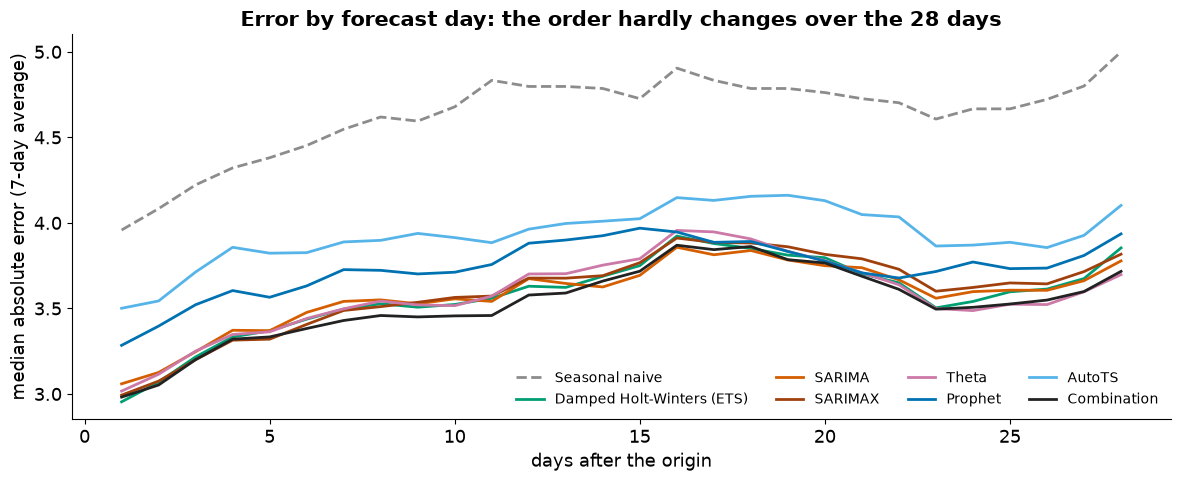

In [10]:
e = fc[fc["origin"].isin(EVAL_ORIGINS)].merge(inp["actuals"], on=["item_id", "date"])
e["day"] = (e["date"] - e["origin"]).dt.days
e["abs_err"] = (e["actual"] - e["forecast"]).abs()
hz = e.groupby(["model", "item_id", "day"])["abs_err"].mean().groupby(["model", "day"]).median().unstack("day")
hz.to_csv(TABLES / "ts_horizon.csv")
written.append(TABLES / "ts_horizon.csv")
STYLE = {"seasonal_naive": ("#8C8C8C", "--"), "ets": ("#009E73", "-"), "sarima": ("#D55E00", "-"), "sarimax": ("#A0410D", "-"),
         "theta": ("#CC79A7", "-"), "prophet": ("#0072B2", "-"), "autots": ("#56B4E9", "-"), "combination": ("#222222", "-"),
         "sarima_07a": ("#D55E00", ":")}
fig, ax = plt.subplots(figsize=(12, 5))
for m in CONT:
    c, ls = STYLE[m]
    ax.plot(hz.columns, hz.loc[m].rolling(7, min_periods=1, center=True).mean(), color=c, ls=ls, lw=2, label=NAME[m])
ax.set_xlabel("days after the origin")
ax.set_ylabel("median absolute error (7-day average)")
ax.set_title("Error by forecast day: the order hardly changes over the 28 days")
ax.legend(ncol=4, frameon=False, fontsize=10)
fig.tight_layout()
fig.savefig(FIGS / "ts_error_by_horizon.png")
written.append(FIGS / "ts_error_by_horizon.png")
plt.show()

## The three main metrics

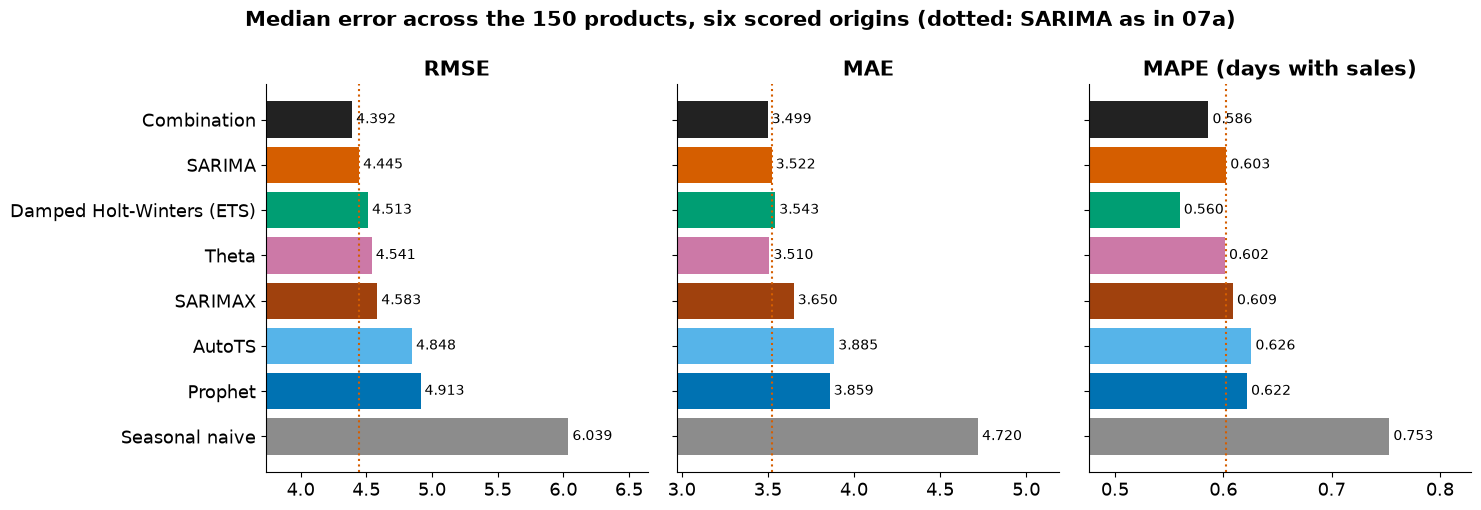

In [11]:
order = head.loc[CONT].sort_values("rmse").index
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
for ax, k, title in zip(axes, ["rmse", "mae", "mape"], ["RMSE", "MAE", "MAPE (days with sales)"]):
    v = head.loc[order, k]
    ax.barh(range(len(order))[::-1], v, color=[STYLE[m][0] for m in order])
    ax.axvline(ref[k], color="#D55E00", ls=":", lw=1.5)
    for y, x in zip(range(len(order))[::-1], v):
        ax.text(x, y, f" {x:.3f}", va="center", fontsize=10)
    ax.set_xlim(v.min() * 0.85, v.max() * 1.1)
    ax.set_title(title)
axes[0].set_yticks(range(len(order))[::-1], [NAME[m] for m in order])
fig.suptitle("Median error across the 150 products, six scored origins (dotted: SARIMA as in 07a)", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "ts_main_metrics.png")
written.append(FIGS / "ts_main_metrics.png")
plt.show()

## Forecast against actual for three products

From the last scored origin, one product per category, with the three best contenders by median RMSE and seasonal
naive.

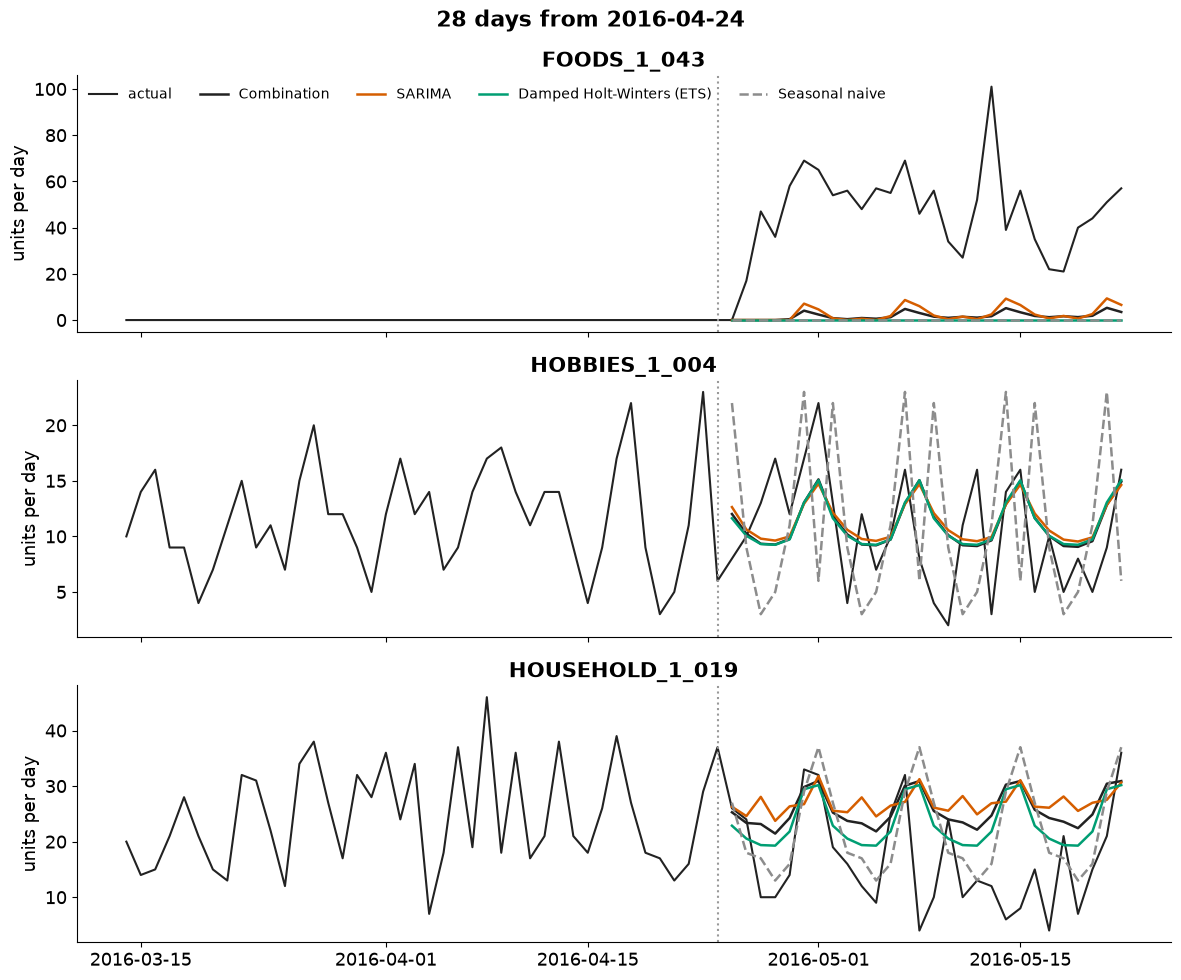

In [12]:
top = [m for m in order if m != "seasonal_naive"][:3]
ex = sample.groupby("category")["item_id"].first().tolist()
last = EVAL_ORIGINS[-1]
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, i in zip(axes, ex):
    d = inp["daily"][i]
    h = d[(d["date"] > last - pd.Timedelta(days=42)) & (d["date"] <= last + pd.Timedelta(days=28))]
    ax.plot(h["date"], h["sales"], color="#222222", lw=1.5, label="actual")
    for m in top + ["seasonal_naive"]:
        x = fc[(fc["item_id"] == i) & (fc["origin"] == last) & (fc["model"] == m)]
        c, ls = STYLE[m]
        ax.plot(x["date"], x["forecast"], color=c, ls=ls, lw=1.8, label=NAME[m])
    ax.axvline(last, color="#999999", ls=":")
    ax.set_title(i)
    ax.set_ylabel("units per day")
axes[0].legend(ncol=5, frameon=False, fontsize=10, loc="upper left")
fig.suptitle(f"28 days from {last.date()}", fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "ts_forecast_examples.png")
written.append(FIGS / "ts_forecast_examples.png")
plt.show()

## The ablation and the ladder, side by side

From 07d and 07c.

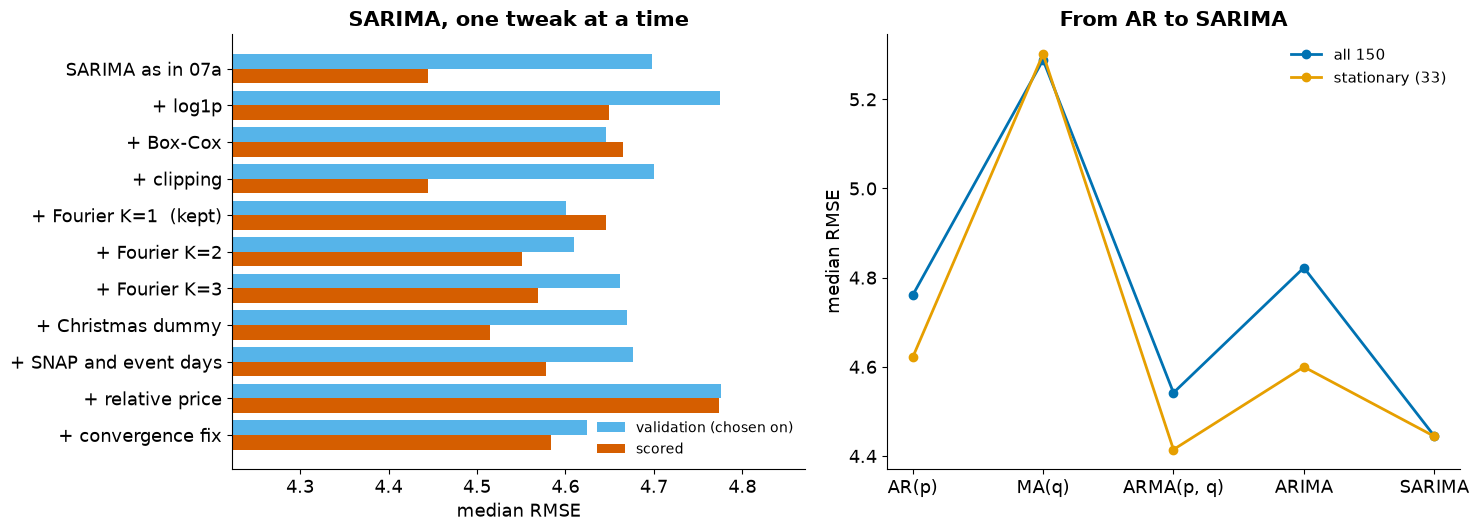

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
if (TABLES / "ts_sarima_ablation.csv").exists():
    a = pd.read_csv(TABLES / "ts_sarima_ablation.csv")
    a = a[a["family"] == "SARIMA"].reset_index(drop=True)
    y = np.arange(len(a))[::-1]
    axes[0].barh(y + 0.2, a["val_rmse"], 0.4, color="#56B4E9", label="validation (chosen on)")
    axes[0].barh(y - 0.2, a["scored_rmse"], 0.4, color="#D55E00", label="scored")
    axes[0].set_yticks(y, [s + ("  (kept)" if k else "") for s, k in zip(a["step"], a["kept"])])
    axes[0].set_xlim(min(a["val_rmse"].min(), a["scored_rmse"].min()) * 0.95, max(a["val_rmse"].max(), a["scored_rmse"].max()) * 1.02)
    axes[0].set_xlabel("median RMSE")
    axes[0].set_title("SARIMA, one tweak at a time")
    axes[0].legend(frameon=False, fontsize=10, loc="lower right")
if (TABLES / "ts_ladder.csv").exists():
    lad = pd.read_csv(TABLES / "ts_ladder.csv")
    for grp, c in zip(lad["products"].unique(), ["#0072B2", "#E69F00"]):
        x = lad[lad["products"] == grp]
        axes[1].plot(x["name"], x["rmse"], "o-", color=c, lw=2, label=grp)
    axes[1].set_ylabel("median RMSE")
    axes[1].set_title("From AR to SARIMA")
    axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "ts_ablation_and_ladder.png")
written.append(FIGS / "ts_ablation_and_ladder.png")
plt.show()

## What AutoTS picked

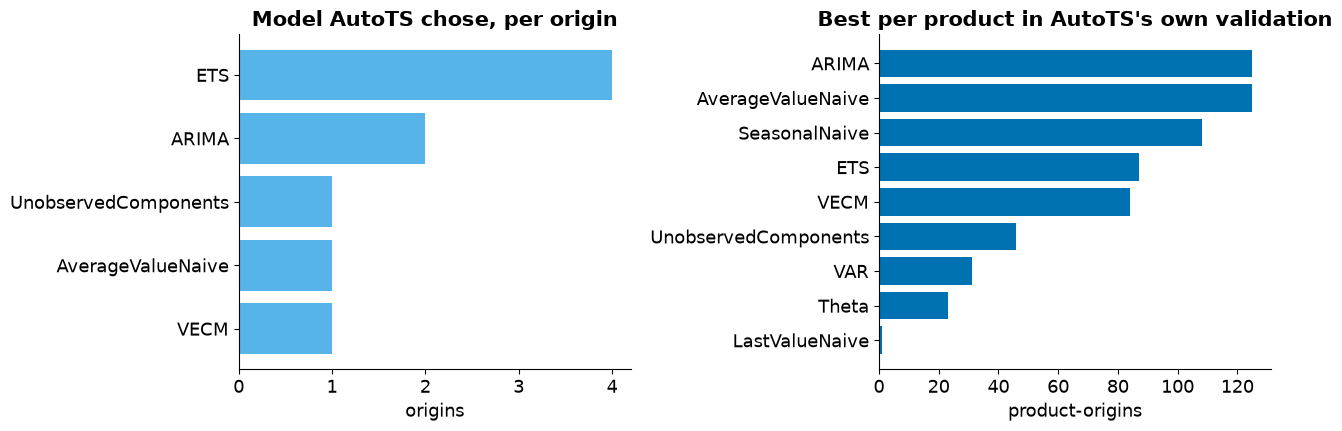

In [14]:
if (TABLES / "ts_autots_choices.csv").exists():
    ch = pd.read_csv(TABLES / "ts_autots_choices.csv")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    a = ch.drop_duplicates("origin")["chosen_model"].value_counts()
    axes[0].barh(a.index[::-1], a.to_numpy()[::-1], color="#56B4E9")
    axes[0].set_title("Model AutoTS chose, per origin")
    axes[0].set_xlabel("origins")
    b = ch["best_for_product"].value_counts()
    axes[1].barh(b.index[::-1], b.to_numpy()[::-1], color="#0072B2")
    axes[1].set_title("Best per product in AutoTS's own validation")
    axes[1].set_xlabel("product-origins")
    fig.tight_layout()
    fig.savefig(FIGS / "ts_autots_choices.png")
    written.append(FIGS / "ts_autots_choices.png")
    plt.show()
else:
    print("no AutoTS choices saved")

## The totals: VARIMA against SARIMA

From 07e, in thousands of units, mean over the six scored origins.

In [15]:
if (TABLES / "ts_varima_scores.csv").exists():
    vt = pd.read_csv(TABLES / "ts_varima_scores.csv")
    print(vt.pivot(index="model", columns="series", values=["rmse", "mase"]).round(3).to_string())

                 rmse                     mase                  
series          FOODS HOBBIES HOUSEHOLD  FOODS HOBBIES HOUSEHOLD
model                                                           
sarima          0.792   0.156     0.303  0.834   0.699     0.928
seasonal_naive  0.855   0.204     0.356  0.913   0.967     1.156
varima          0.777   0.151     0.294  0.837   0.678     0.891


## Save everything for the dashboard

In [16]:
out = fc.merge(inp["actuals"], on=["item_id", "date"]).merge(sample[["item_id", "category"]], on="item_id")
out["kind"] = out["model"].map(KIND)
out.to_parquet(TABLES / "ts_forecasts.parquet", index=False)
written.append(TABLES / "ts_forecasts.parquet")
pi.to_csv(TABLES / "ts_item_scores.csv", index=False)
written.append(TABLES / "ts_item_scores.csv")
assert out.groupby(["model", "item_id", "origin"]).size().eq(28).all() and out["forecast"].notna().all()
assert set(out["origin"]) <= set(tm.ALL_ORIGINS) and pi.groupby("model")["item_id"].nunique().eq(150).all()

## What we found

SARIMA is still the most accurate time-series model on RMSE, and tuning did not change it. Its scored median RMSE is
4.445 and MAE 3.522, exactly the 07a numbers, because no SARIMA tweak passed on the validation dates (07d): the one
that did, a yearly Fourier pair, became SARIMAX. So the most accurate model beats SARIMA as in 07a by nothing at all,
and that is the honest result of the tuning.

Close behind come the combination (4.523 / 3.567), damped ETS (4.513 / 3.543) and Theta (4.541 / 3.510). On MAE Theta
is the best by a hair (3.510), and on MAPE damped ETS is clearly best (0.560 against 0.603), because its forecasts sit a
little lower and MAPE punishes over-forecasts on slow days more. Every fitted contender is far ahead of repeating
last week (RMSE 6.039).

The median over products hides a split. Taken product by product, the combination has a smaller RMSE than SARIMA for
63% of products (median difference -0.024, Holm p = 0.079) and a smaller MAE for 68% (p = 0.003); on MAE and MAPE it
is significantly better. But on the products where it loses it loses by more, so the median RMSE across products is
higher. Which of the two is "better" depends on the question: the typical product, or the typical error. We decided
before the run that the headline is the median RMSE across products, and we keep that.

Two contenders are significantly worse than SARIMA on RMSE after Holm correction: SARIMAX (its yearly term hurts on the
winter and spring dates, as 07d found) and AutoTS. Prophet is worse on MAE and MAPE. Of the building blocks, ARMA comes
closest (4.542), and none of them is better than SARIMA: the weekly seasonal terms are worth about 0.4 in RMSE over
ARIMA, as 07c showed.

No single model wins most products. On RMSE Prophet is best for 49 of the 150, ETS for 30, SARIMA for 22, the
combination for 19 and SARIMAX for 18. Prophet wins the most products and still has a poor median: where it
misses, it misses by more. Per category SARIMA has the lowest RMSE in FOODS (7.998) and HOUSEHOLD (3.646), and ETS in
HOBBIES (3.131).

The error grows with the horizon for every model: SARIMA's median absolute error is 3.37 in the first week and 3.61 in
the fourth, and the last two days are the worst (4.25 on day 28), because every origin is a Sunday, so days 27
and 28 are always a Saturday and a Sunday, the busiest days of the week. In the first week ETS, the
combination, Theta and SARIMAX are all within 0.04 of each other; by day 28 SARIMA is among the best.

On the three category totals, in
thousands of units, VARIMA is a little better than SARIMA on HOBBIES (MASE 0.678 against 0.699) and HOUSEHOLD (0.891
against 0.928) and level on FOODS (0.837 against 0.834); the one link between the totals that survives a Granger test
is FOODS to HOUSEHOLD (07e).

By the rule we wrote down before this table was seen, the winner for the rest of the project is the contender with
the lowest scored median RMSE: SARIMA. 09 fits it on all 726 products, and 10 and 11 use it in place of LightGBM.

## What this means for a planner

For a store planner the choice between the good time-series models matters much less than having one of them at
all. Moving from "repeat last week" to SARIMA cuts the typical daily error from 6.0 to 4.4 units per product, about a
quarter. Moving from SARIMA to the next best model changes it by a few hundredths of a unit, less than 2%, and which
one comes out ahead depends on the measure.

Some practical points follow.

- **Use SARIMA, or the combination if a stable result matters more.** SARIMA has the lowest median RMSE, so it is
  the forecast behind the stock work in 11. The average of SARIMAX, ETS and Theta beats it on about two products in
  three and on MAE and MAPE, but loses by more on the rest. It is the safer choice when a planner cares about the
  typical product rather than the typical error, and it needs no order search.
- **Watch for under-forecasting on slow days.** ETS has the best MAPE because it forecasts a little lower. On a
  product that sells two units a day, a forecast of three is a 50% error, so MAPE rewards caution, while stock
  decisions punish it.
- **The last days of a 28-day forecast are the least reliable**, and in this backtest they fall on a weekend, when
  most units are sold. Orders placed weekly, with a fresh forecast each week, avoid relying on day 28.
- **Calendar effects are real but small.** SNAP lifts a FOODS product's day by about 8%, events lower it by about 3%,
  and Christmas closes the store. Adding them as regressors did not improve the 28-day forecast, because the weekly
  terms already carry most of the pattern. A planner should still adjust for Christmas and SNAP by hand where the
  forecast cannot see them.
- **An automatic model search is not a shortcut.** AutoTS, with a search we could afford, did worse than any of the
  hand-picked models, and picked a different model at almost every forecast date.

## Why LightGBM, XGBoost and the GRU are not here

This comparison is about time-series models: models that forecast a product from its own past (and, for SARIMAX and
Prophet, a few calendar and price regressors). LightGBM, XGBoost and the GRU learn one model across many products
from engineered features: lags, rolling means, calendar and price columns, fitted on all products at once. That is
machine learning rather than time-series modelling, and this project is about time-series models, so they were
removed from it. Their place in the stock notebooks goes to the winner of this table, which `09` fits on all 726
products.

In [17]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\tables\ts_capped_forecasts.csv 0 KB
outputs\tables\ts_combination_members.csv 0 KB
outputs\tables\ts_combination_weights.csv 27 KB
outputs\tables\ts_headline.csv 3 KB
outputs\tables\ts_headline_by_category.csv 6 KB
outputs\tables\ts_best_model.json 0 KB
outputs\tables\ts_tests.csv 8 KB
outputs\tables\ts_wins.csv 0 KB
outputs\tables\ts_horizon.csv 8 KB
outputs\figures\ts_error_by_horizon.png 147 KB
outputs\figures\ts_main_metrics.png 95 KB
outputs\figures\ts_forecast_examples.png 296 KB
outputs\figures\ts_ablation_and_ladder.png 145 KB
outputs\figures\ts_autots_choices.png 71 KB
outputs\tables\ts_forecasts.parquet 4,692 KB
outputs\tables\ts_item_scores.csv 324 KB
